# 🕵️ Fake vs Real Image Detection using Transfer Learning
### EfficientNetB0 pretrained on ImageNet · TensorFlow / Keras

---

## 🎯 Project Overview

With the rise of **Generative AI (GANs, Diffusion Models)**, detecting AI-generated fake images has become a critical problem in media, journalism, and security.

In this project we use **Transfer Learning** to fine-tune **EfficientNetB0** (pretrained on ImageNet) to distinguish between:
- ✅ **Real images** — actual photographs
- ❌ **Fake images** — AI-generated images (GAN-generated)

## 🔬 What is Transfer Learning?
Instead of training a deep CNN from scratch (which needs millions of images & days of compute), we:
1. Take **EfficientNetB0** already trained on 1.2M ImageNet images
2. **Freeze** its learned feature extraction layers
3. Add a new **classification head** for our binary task
4. Train in **two phases**: head-only → then fine-tune top layers

**Dataset:** CIFAKE — Real and AI-Generated Synthetic Images (Kaggle)  
**Runtime:** ~25–35 min on Colab Free GPU (T4)  

> ⚡ **Before running:** Go to `Runtime > Change runtime type > T4 GPU`

---
## 📦 Step 1: Install Dependencies & Import Libraries

In [1]:
# Install kaggle API to download dataset
!pip install kaggle -q

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import os, warnings, pathlib
warnings.filterwarnings('ignore')

from tensorflow.keras import layers, models, callbacks
from tensorflow.keras.applications import EfficientNetB3
from tensorflow.keras.preprocessing import image_dataset_from_directory
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

print('✅ TensorFlow:', tf.__version__)
print('✅ GPU:', tf.config.list_physical_devices("GPU"))

✅ TensorFlow: 2.19.0
✅ GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


---
## 🔑 Step 2: Download Dataset from Kaggle

We use the **CIFAKE dataset** — 60,000 real + 60,000 AI-generated images.

**To get your Kaggle API key:**
1. Go to https://www.kaggle.com → Account → Create New API Token
2. It downloads a `kaggle.json` file
3. Upload it when the cell below asks

In [2]:
# Upload your kaggle.json API key
from google.colab import files
print('📂 Please upload your kaggle.json file:')
uploaded = files.upload()

# Setup kaggle credentials
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json
print('✅ Kaggle API configured!')

📂 Please upload your kaggle.json file:


Saving kaggle.json to kaggle.json
✅ Kaggle API configured!


In [3]:
# Download CIFAKE dataset
!kaggle datasets download -d birdy654/cifake-real-and-ai-generated-synthetic-images
!unzip -q cifake-real-and-ai-generated-synthetic-images.zip -d cifake
print('✅ Dataset downloaded and extracted!')
!find cifake -type d | head -20

Dataset URL: https://www.kaggle.com/datasets/birdy654/cifake-real-and-ai-generated-synthetic-images
License(s): other
  0% 0.00/105M [00:00<?, ?B/s]
100% 105M/105M [00:00<00:00, 1.73GB/s]
✅ Dataset downloaded and extracted!
cifake
cifake/train
cifake/train/REAL
cifake/train/FAKE
cifake/test
cifake/test/REAL
cifake/test/FAKE


---
## 🖼️ Step 3: Explore & Visualize the Dataset

  train/REAL: 50000 images
  train/FAKE: 50000 images
  test/REAL: 10000 images
  test/FAKE: 10000 images



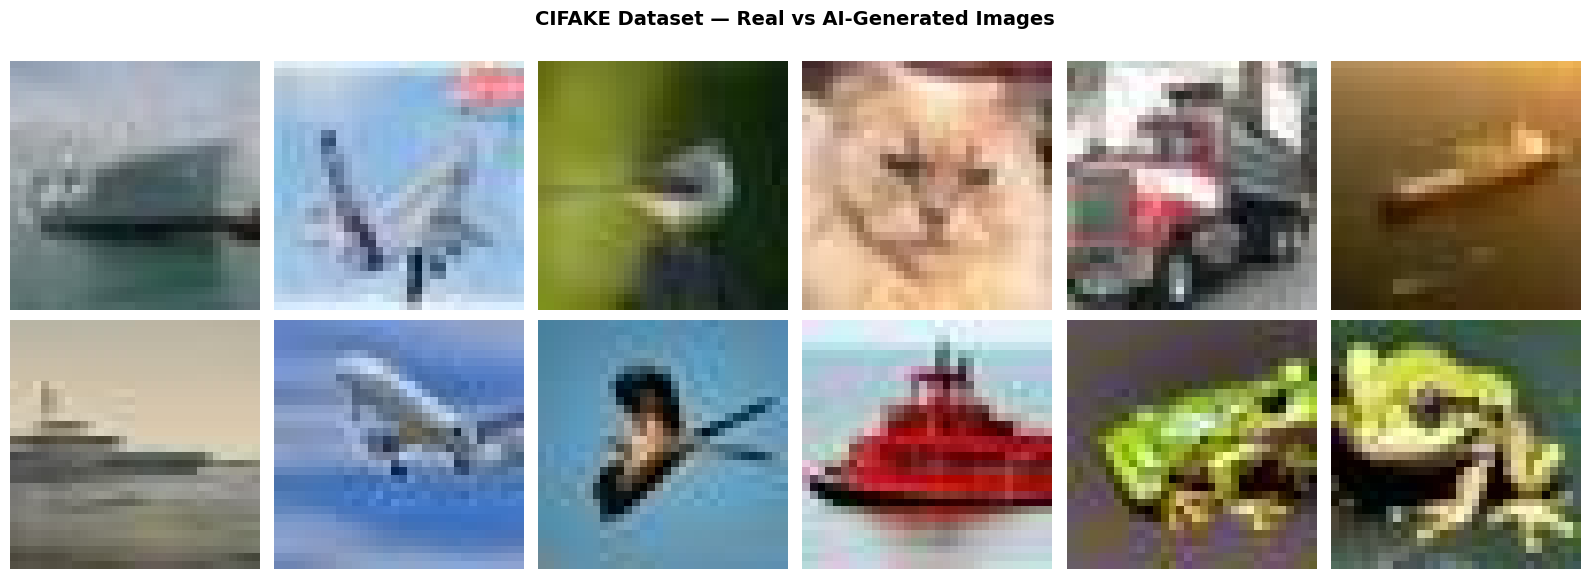

In [4]:
import matplotlib.image as mpimg

# Adjust paths based on dataset structure
TRAIN_DIR = 'cifake/train'
TEST_DIR  = 'cifake/test'

# Count images
for split in ['train', 'test']:
    base = f'cifake/{split}'
    for cls in os.listdir(base):
        count = len(os.listdir(f'{base}/{cls}'))
        print(f'  {split}/{cls}: {count} images')

print()

# Visualize sample images side by side
fig, axes = plt.subplots(2, 6, figsize=(16, 6))
fig.suptitle('CIFAKE Dataset — Real vs AI-Generated Images', fontsize=14, fontweight='bold')

for row, cls in enumerate(['REAL', 'FAKE']):
    folder = f'{TRAIN_DIR}/{cls}'
    images = os.listdir(folder)[:6]
    for col, img_name in enumerate(images):
        img = mpimg.imread(f'{folder}/{img_name}')
        axes[row, col].imshow(img)
        axes[row, col].axis('off')
        if col == 0:
            axes[row, col].set_ylabel(
                '✅ REAL' if cls == 'REAL' else '❌ FAKE (AI)',
                fontsize=12, fontweight='bold',
                color='green' if cls == 'REAL' else 'red'
            )
plt.tight_layout()
plt.show()

---
## ⚙️ Step 4: Build the Data Pipeline

In [5]:
# Config
IMG_SIZE = (300, 300)
BATCH_SIZE = 16
SEED       = 42

# Training set
train_ds = image_dataset_from_directory(
    TRAIN_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    seed=SEED,
    label_mode='binary',
    shuffle=True
)

# Test / validation set
test_ds = image_dataset_from_directory(
    TEST_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    seed=SEED,
    label_mode='binary',
    shuffle=False
)

CLASS_NAMES = train_ds.class_names
print('✅ Classes:', CLASS_NAMES)
print(f'✅ Train batches: {len(train_ds)} | Test batches: {len(test_ds)}')

# Cache & prefetch for performance
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.take(500).prefetch(AUTOTUNE)
test_ds  = test_ds.prefetch(AUTOTUNE)

Found 100000 files belonging to 2 classes.
Found 20000 files belonging to 2 classes.
✅ Classes: ['FAKE', 'REAL']
✅ Train batches: 6250 | Test batches: 1250


---
## 🔄 Step 5: Data Augmentation

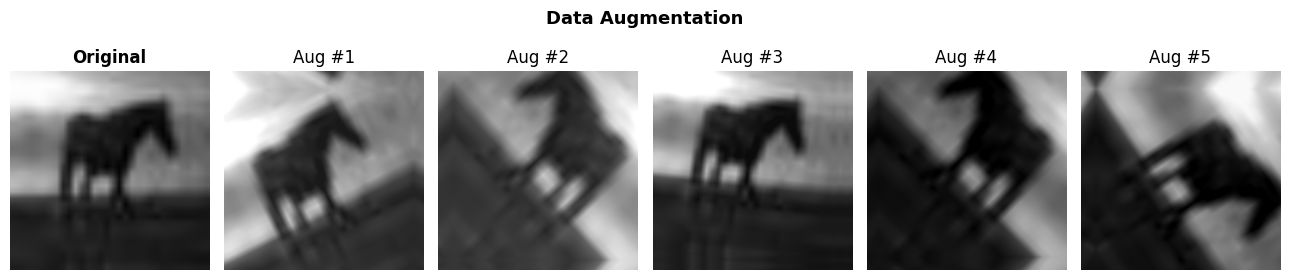

In [6]:
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip('horizontal'),
    layers.RandomRotation(0.2),       # was 0.1
    layers.RandomZoom(0.2),           # was 0.1
    layers.RandomContrast(0.2),       # was 0.1
    layers.RandomBrightness(0.15),    # NEW
    layers.RandomTranslation(0.1, 0.1) # NEW
])

# Show augmentation effect
sample_imgs, _ = next(iter(train_ds))
orig = sample_imgs[0:1]

plt.figure(figsize=(13, 3))
plt.subplot(1, 6, 1)
plt.imshow(orig[0].numpy().astype('uint8'))
plt.title('Original', fontweight='bold'); plt.axis('off')
for i in range(5):
    aug = data_augmentation(orig, training=True)
    plt.subplot(1, 6, i+2)
    plt.imshow(aug[0].numpy().astype('uint8'))
    plt.title(f'Aug #{i+1}'); plt.axis('off')
plt.suptitle('Data Augmentation', fontsize=13, fontweight='bold')
plt.tight_layout(); plt.show()

---
## 🏗️ Step 6: Build the Transfer Learning Model

```
Input (224x224x3)
    ↓
Data Augmentation
    ↓
EfficientNetB0 (pretrained ImageNet, FROZEN)
    ↓
Global Average Pooling
    ↓
Dropout (0.3)
    ↓
Dense(128, relu)
    ↓
Dense(1, sigmoid)  →  FAKE / REAL
```

In [7]:
def build_model(trainable_base=False):
    # Load pretrained EfficientNetB0 (no top classifier)
    base_model = EfficientNetB3(
        weights='imagenet',
        include_top=False,
        input_shape=(300, 300, 3)  # B3 works best at 300x300
    )
    base_model.trainable = trainable_base

    inputs = layers.Input(shape=(*IMG_SIZE, 3))
    x = data_augmentation(inputs)
    # EfficientNet has its own preprocessing built in
    x = base_model(x, training=trainable_base)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.BatchNormalization()(x)   # ADD THIS
    x = layers.Dropout(0.4)(x)           # increase dropout slightly
    x = layers.Dense(256, activation='relu')(x)  # was 128, now 256
    x = layers.BatchNormalization()(x)   # ADD THIS
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(1, activation='sigmoid')(x)

    model = models.Model(inputs, outputs)
    return model, base_model

model, base_model = build_model(trainable_base=False)
model.summary()

43941136/43941136 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 300, 300, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 300, 300, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb3 (Functional)     │ (None, 10, 10, 1536)   │    10,783,535 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1536)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1536)           │         6,144 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1536)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       393,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,184,432 (42.67 MB)

 Trainable params: 397,313 (1.52 MB)

 Non-trainable params: 10,787,119 (41.15 MB)

---
## 🔒 Step 7: Phase 1 — Train Classification Head (Base Frozen)

In [8]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

cb_early = callbacks.EarlyStopping(monitor='val_accuracy', patience=4, restore_best_weights=True)
cb_lr    = callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, verbose=1)

print('🔒 Phase 1: Training classification head (base model frozen)...')
history1 = model.fit(
    train_ds,
    validation_data=test_ds,
    epochs=15,
    callbacks=[cb_early, cb_lr]
)

🔒 Phase 1: Training classification head (base model frozen)...
Epoch 1/15
500/500 ━━━━━━━━━━━━━━━━━━━━ 251s 464ms/step - accuracy: 0.7143 - loss: 0.6528 - val_accuracy: 0.8432 - val_loss: 0.3586 - learning_rate: 0.0010
Epoch 2/15
500/500 ━━━━━━━━━━━━━━━━━━━━ 228s 457ms/step - accuracy: 0.7932 - loss: 0.4591 - val_accuracy: 0.8611 - val_loss: 0.3325 - learning_rate: 0.0010
Epoch 3/15
500/500 ━━━━━━━━━━━━━━━━━━━━ 229s 458ms/step - accuracy: 0.8025 - loss: 0.4278 - val_accuracy: 0.8593 - val_loss: 0.3355 - learning_rate: 0.0010
Epoch 4/15
500/500 ━━━━━━━━━━━━━━━━━━━━ 229s 458ms/step - accuracy: 0.8073 - loss: 0.4162 - val_accuracy: 0.8672 - val_loss: 0.3167 - learning_rate: 0.0010
Epoch 5/15
500/500 ━━━━━━━━━━━━━━━━━━━━ 229s 458ms/step - accuracy: 0.8091 - loss: 0.4002 - val_accuracy: 0.8616 - val_loss: 0.3284 - learning_rate: 0.0010
Epoch 6/15
500/500 ━━━━━━━━━━━━━━━━━━━━ 230s 460ms/step - accuracy: 0.8048 - loss: 0.4136 - val_accuracy: 0.8738 - val_loss: 0.3048 - learning_rate: 0.0010
E

---
## 🔓 Step 8: Phase 2 — Fine-Tune Top Layers of EfficientNet

In [9]:
# Unfreeze top 30 layers of the base model
base_model.trainable = True
for layer in base_model.layers[:-60]:
    layer.trainable = False

trainable_count = sum([tf.size(w).numpy() for w in model.trainable_weights])
print(f'🔓 Fine-tuning top 30 layers | Trainable params: {trainable_count:,}')

# Use lower LR for fine-tuning
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

cb_early2 = callbacks.EarlyStopping(monitor='val_accuracy', patience=4, restore_best_weights=True)

print('🔓 Phase 2: Fine-tuning...')
history2 = model.fit(
    train_ds,
    validation_data=test_ds,
    epochs=15,
    callbacks=[cb_early2]
)

🔓 Fine-tuning top 30 layers | Trainable params: 5,650,767
🔓 Phase 2: Fine-tuning...
Epoch 1/15
500/500 ━━━━━━━━━━━━━━━━━━━━ 277s 509ms/step - accuracy: 0.7793 - loss: 0.4804 - val_accuracy: 0.8308 - val_loss: 0.3726
Epoch 2/15
500/500 ━━━━━━━━━━━━━━━━━━━━ 250s 500ms/step - accuracy: 0.8067 - loss: 0.4200 - val_accuracy: 0.8535 - val_loss: 0.3294
Epoch 3/15
500/500 ━━━━━━━━━━━━━━━━━━━━ 249s 499ms/step - accuracy: 0.8228 - loss: 0.3964 - val_accuracy: 0.8700 - val_loss: 0.3017
Epoch 4/15
500/500 ━━━━━━━━━━━━━━━━━━━━ 251s 502ms/step - accuracy: 0.8457 - loss: 0.3619 - val_accuracy: 0.8788 - val_loss: 0.2839
Epoch 5/15
500/500 ━━━━━━━━━━━━━━━━━━━━ 251s 503ms/step - accuracy: 0.8517 - loss: 0.3413 - val_accuracy: 0.8893 - val_loss: 0.2672
Epoch 6/15
500/500 ━━━━━━━━━━━━━━━━━━━━ 250s 501ms/step - accuracy: 0.8559 - loss: 0.3381 - val_accuracy: 0.8970 - val_loss: 0.2515
Epoch 7/15
500/500 ━━━━━━━━━━━━━━━━━━━━ 251s 502ms/step - accuracy: 0.8568 - loss: 0.3187 - val_accuracy: 0.9003 - val_loss:

---
## 📊 Step 9: Plot Training Curves

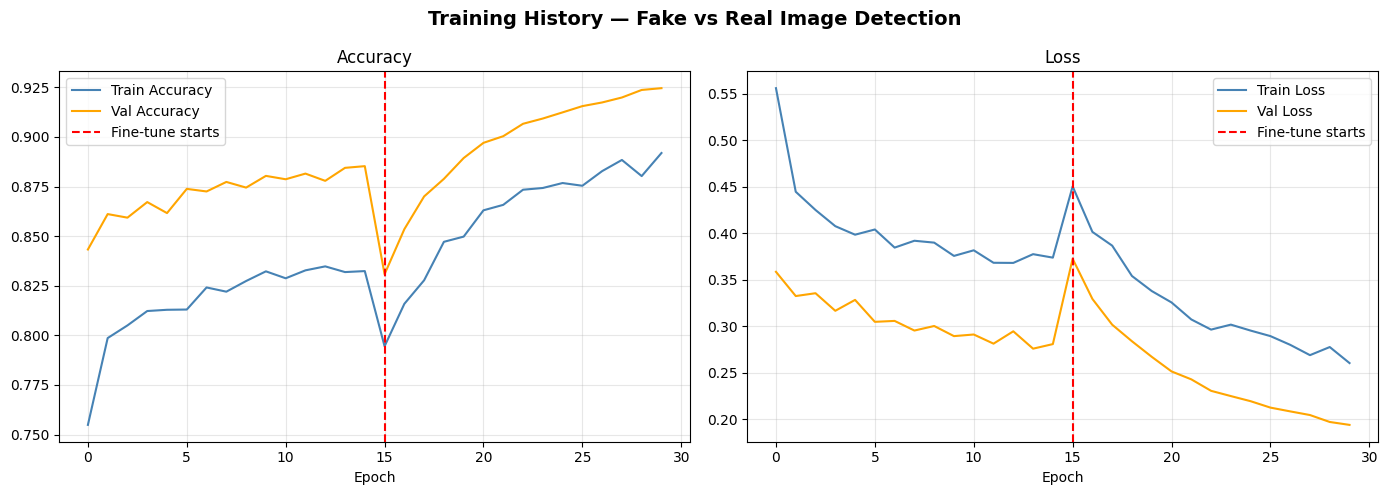

In [10]:
def plot_history(h1, h2):
    acc  = h1.history['accuracy']  + h2.history['accuracy']
    vacc = h1.history['val_accuracy'] + h2.history['val_accuracy']
    loss = h1.history['loss']  + h2.history['loss']
    vloss= h1.history['val_loss'] + h2.history['val_loss']
    phase_split = len(h1.history['accuracy'])

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
    fig.suptitle('Training History — Fake vs Real Image Detection', fontsize=14, fontweight='bold')

    ax1.plot(acc, label='Train Accuracy', color='steelblue')
    ax1.plot(vacc, label='Val Accuracy', color='orange')
    ax1.axvline(phase_split, color='red', linestyle='--', label='Fine-tune starts')
    ax1.set_title('Accuracy'); ax1.set_xlabel('Epoch'); ax1.legend(); ax1.grid(True, alpha=0.3)

    ax2.plot(loss, label='Train Loss', color='steelblue')
    ax2.plot(vloss, label='Val Loss', color='orange')
    ax2.axvline(phase_split, color='red', linestyle='--', label='Fine-tune starts')
    ax2.set_title('Loss'); ax2.set_xlabel('Epoch'); ax2.legend(); ax2.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

plot_history(history1, history2)

---
## 📈 Step 10: Evaluate — Confusion Matrix & Classification Report

1250/1250 ━━━━━━━━━━━━━━━━━━━━ 164s 129ms/step

🎯 Test Accuracy : 92.45%
📉 Test Loss     : 0.1941

📋 Classification Report:
              precision    recall  f1-score   support

        FAKE       0.92      0.93      0.93     10000
        REAL       0.93      0.92      0.92     10000

    accuracy                           0.92     20000
   macro avg       0.92      0.92      0.92     20000
weighted avg       0.92      0.92      0.92     20000



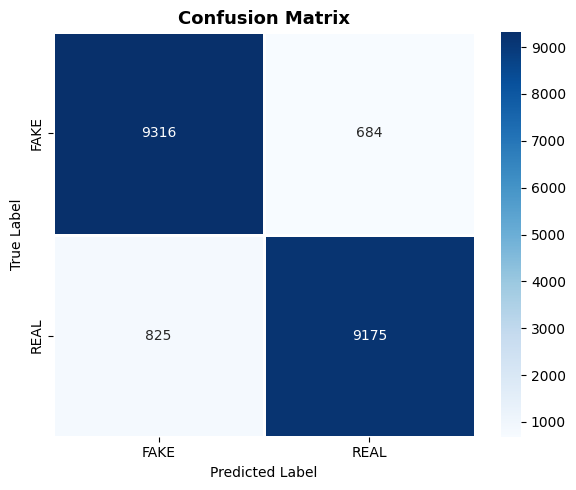

In [11]:
# Get predictions
y_pred_probs = model.predict(test_ds, verbose=1)
y_pred = (y_pred_probs > 0.5).astype(int).flatten()
y_true = np.concatenate([y.numpy() for _, y in test_ds]).flatten().astype(int)

# Evaluation
loss, acc = model.evaluate(test_ds, verbose=0)
print(f'\n🎯 Test Accuracy : {acc*100:.2f}%')
print(f'📉 Test Loss     : {loss:.4f}\n')

print('📋 Classification Report:')
print(classification_report(y_true, y_pred, target_names=CLASS_NAMES))

# Confusion matrix
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
            linewidths=1, linecolor='white')
plt.title('Confusion Matrix', fontsize=13, fontweight='bold')
plt.xlabel('Predicted Label'); plt.ylabel('True Label')
plt.tight_layout(); plt.show()

---
## 🔍 Step 11: Visualize Predictions on Test Images

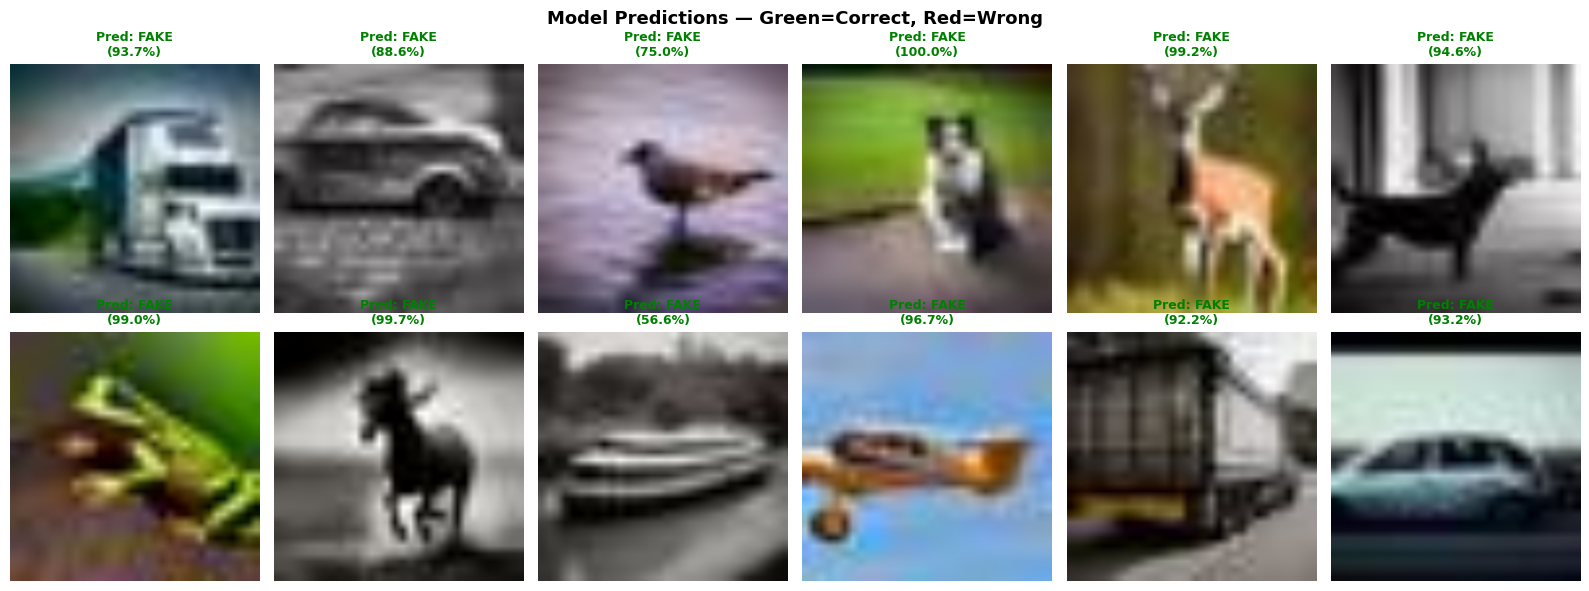

In [12]:
sample_imgs, sample_labels = next(iter(test_ds))
preds = model.predict(sample_imgs, verbose=0)

plt.figure(figsize=(16, 6))
for i in range(12):
    ax = plt.subplot(2, 6, i + 1)
    plt.imshow(sample_imgs[i].numpy().astype('uint8'))
    pred_class = CLASS_NAMES[int(preds[i] > 0.5)]
    true_class = CLASS_NAMES[int(sample_labels[i])]
    confidence = preds[i][0] if pred_class == CLASS_NAMES[1] else 1 - preds[i][0]
    correct = pred_class == true_class
    color = 'green' if correct else 'red'
    plt.title(f'Pred: {pred_class}\n({confidence*100:.1f}%)',
              color=color, fontsize=9, fontweight='bold')
    plt.axis('off')

plt.suptitle('Model Predictions — Green=Correct, Red=Wrong', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

---
## 💾 Step 12: Save the Model

In [13]:
model.save('fake_real_detector.h5')
print('✅ Model saved as fake_real_detector.h5')

# Download model to your local machine
from google.colab import files
files.download('fake_real_detector.h5')

TypeError: cannot pickle 'module' object

---
## 🧪 Step 13: Test on Your Own Image!

📂 Upload any image to test (real photo or AI-generated):


Saving IMG.jpg to IMG.jpg


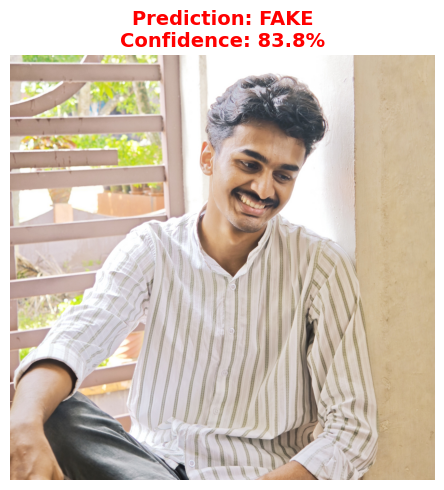

In [14]:
from google.colab import files
from tensorflow.keras.preprocessing import image as keras_image

print('📂 Upload any image to test (real photo or AI-generated):')
uploaded = files.upload()

for fname in uploaded.keys():
    img = keras_image.load_img(fname, target_size=IMG_SIZE)
    img_array = keras_image.img_to_array(img)
    img_array = tf.expand_dims(img_array, 0)

    pred = model.predict(img_array, verbose=0)[0][0]
    label = CLASS_NAMES[int(pred > 0.5)]
    confidence = pred if label == CLASS_NAMES[1] else 1 - pred

    plt.figure(figsize=(5, 5))
    plt.imshow(keras_image.load_img(fname))
    color = 'red' if label == 'FAKE' else 'green'
    plt.title(f'Prediction: {label}\nConfidence: {confidence*100:.1f}%',
              fontsize=14, fontweight='bold', color=color)
    plt.axis('off')
    plt.tight_layout()
    plt.show()

---
## 📝 Summary

| Step | What we did |
|------|-------------|
| Dataset | CIFAKE — 60K real + 60K AI-generated images |
| Base Model | EfficientNetB0 pretrained on ImageNet (1.2M images) |
| Phase 1 | Froze base model → trained new classification head |
| Phase 2 | Unfroze top 30 layers → fine-tuned with low LR |
| Output | Binary classifier: REAL vs FAKE (AI-generated) |

### 💡 Key Transfer Learning Concepts Demonstrated
- **Feature extraction** — reusing ImageNet-learned features
- **Frozen layers** — preserving pretrained weights initially
- **Fine-tuning** — gradually adapting to new domain
- **Learning rate scheduling** — lower LR during fine-tune to avoid forgetting

### 🔮 Possible Extensions
- Try with **Stable Diffusion** generated images
- Use **Grad-CAM** to visualize what the model focuses on
- Deploy as a **web app** using Gradio or Streamlit